# Cohort and clinical follow-up of the myeloid cfRNA signal

This companion to [gene_interactions_interpretation.ipynb](gene_interactions_interpretation.ipynb) asks whether the SPI1–MNDA–LYZ association persists within cohorts and after demographic/composition adjustment, and whether the signal varies with Xpert Ultra category **among TB-positive participants**. It does not retrain or select a classifier.

## Summary

- The TB association remains positive after broad composition, cohort, age, sex and HIV adjustment in all three splits. Its magnitude varies across cohort/split strata.
- Resolving monocyte and neutrophil contributions separately weakens the adjusted TB association in training and validation. This makes the conclusion sensitive to how finely cell composition is represented.
- The three-gene signal does **not** show a reproducible association with sputum Xpert Ultra category within TB-positive participants. None of the three primary burden trends passes the exploratory BH correction.

All intervals and tests are exploratory because these genes were selected using TB status and these datasets have already been inspected.

## 1. Methods and sources

- **RNA composition:** reuse the existing plasma estimates in `Files_For_Manuscript/discovery_cell_types.tsv`, through the interpretation notebook's checked exports. All 251 participants are covered. `cto_wb.txt` contains distinct whole-blood estimates for an optional paired comparison; it is not the composition input here.
- **Expression signal:** the existing unweighted mean of training-standardized SPI1, MNDA and LYZ. One unit is one mean gene-level training z score, not one standard deviation of the composite. Reuse the exported score without rescaling within cohorts.
- **Primary comparison:** fit the signal as an outcome, with TB status as the predictor, separately in training, test and validation. Compare cohort adjustment, cohort plus the three existing composition log ratios, and additional age (per decade), sex and HIV adjustment. The coefficient is the adjusted TB-positive minus TB-negative signal difference. Composition adjustment addresses a statistical mixture question, not a causal direct effect.
- **Cohort checks:** repeat the final model within each cohort/split; test a TB-by-cohort interaction where both GHL and R2D2 are represented. Do not include both cohort and nested site indicators. Validation contains TBSQUARE only.
- **Sensitivity checks:** add within-cohort centered log10 exonic read depth; separately split the myeloid fraction into monocyte, neutrophil and other-myeloid sources. Use log ratios to the same remaining-source denominator, not raw fractions that sum to one.
- **Clinical comparison:** the manuscript identifies `semiquant` as **Xpert Ultra semiquantitative result** ([Figure 2G and caption](https://pmc.ncbi.nlm.nih.gov/articles/PMC11164910/); the local [Figure_2.ipynb](Figure_2.ipynb) uses the same label). Restrict to TB-positive participants with Low/Medium/High results. Encode these ordered categories as 0/1/2 for a trend check, not calibrated bacterial counts. Missing values and TB-negative participants are excluded, never assigned a zero burden. Show the categorical distributions and Spearman correlation alongside the ordinal slope.
- **Uncertainty:** OLS with HC3 heteroskedasticity-robust covariance and residual-degree-of-freedom t intervals. Report 95% intervals, sample size, residual degrees of freedom and exact model formulas. Adjust the three primary fully adjusted TB tests with Benjamini–Hochberg; separately adjust the three primary fully adjusted burden tests. Sensitivity/heterogeneity tests are descriptive exploratory checks, not new confirmatory claims.

### Key assumptions and limits

Age is linear, composition enters through log ratios, and the ordinal trend assumes equally spaced category steps. These small strata have limited power, especially for HIV adjustment. Same-RNA deconvolution is an estimated RNA-source mixture, not measured cell counts; residual association does not establish cell-intrinsic activation. The expression uses the original split-specific VST underlying the model. A future independent study is needed for validation of these hypotheses.

In [1]:
import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

current = Path.cwd().resolve()
REPOSITORY = next(p for p in [current, *current.parents]
                  if (p / "Files_For_Manuscript/counts.train.tsv").exists())
DATA = REPOSITORY / "Files_For_Manuscript"
FOCUSED = REPOSITORY / "Figure_Output/Gene_Interactions/focused"
OUTPUT = FOCUSED
OUTPUT.mkdir(parents=True, exist_ok=True)
SPLIT_NAMES = {"train": "Training", "test": "Test", "val": "Validation"}
COLORS = {"train": "#28778E", "test": "#AD597F", "val": "#B17E24"}
SEED = 87
sns.set_theme(style="ticks", context="paper")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                    "axes.labelsize": 10, "axes.titlesize": 11,
                    "axes.spines.top": False, "axes.spines.right": False,
                    "figure.dpi": 110, "savefig.dpi": 250, "pdf.fonttype": 42})

def save_figure(figure, name):
    for suffix in ["png", "pdf"]:
        figure.savefig(OUTPUT / f"cohort_clinical_{name}.{suffix}", bbox_inches="tight")

## 2. Load the existing score and audit the participant groups

Match by sample ID and require complete demographics. All 251 samples must agree with the exported split, cohort and TB labels. The coverage table makes the small within-cohort denominators visible.

In [2]:
analysis = pd.read_csv(FOCUSED / "myeloid_analysis_inputs.csv", index_col="sample_id")
metadata = pd.concat([
    pd.read_csv(DATA / f"metadata.{split}.tsv", sep="\t", index_col="sample_id").assign(split=split)
    for split in SPLIT_NAMES
])
assert analysis.index.is_unique and metadata.index.is_unique
assert set(analysis.index) == set(metadata.index)
metadata = metadata.loc[analysis.index]
for column in ["split", "cohort", "tb"]:
    assert analysis[column].equals(metadata[column])
np.testing.assert_allclose(analysis.three_gene_signal, analysis[["SPI1", "MNDA", "LYZ"]].mean(axis=1))
analysis = analysis.join(metadata[["age", "sex", "hiv", "semiquant", "exonic_reads"]])
assert analysis[["age", "sex", "hiv", "exonic_reads"]].notna().all().all()
assert set(analysis.sex) == {"Female", "Male"} and set(analysis.hiv) == {"Negative", "Positive"}
analysis["age_decades"] = analysis.age / 10
analysis["male"] = analysis.sex.eq("Male").astype(int)
analysis["hiv_positive"] = analysis.hiv.eq("Positive").astype(int)
assert analysis.exonic_reads.gt(0).all()
analysis["log10_exonic_reads"] = np.log10(analysis.exonic_reads)
analysis["depth_within_cohort"] = analysis.log10_exonic_reads - analysis.groupby(
    ["split", "cohort"]).log10_exonic_reads.transform("mean")

coverage = analysis.groupby(["split", "cohort"], sort=False).agg(
    n=("tb_positive", "size"), tb_positive=("tb_positive", "sum"),
    hiv_positive=("hiv_positive", "sum"), male=("male", "sum"),
    median_age=("age", "median"), min_age=("age", "min"), max_age=("age", "max"))
coverage["tb_negative"] = coverage.n - coverage.tb_positive
coverage.to_csv(OUTPUT / "cohort_clinical_participant_coverage.csv")
display(coverage[["n", "tb_negative", "tb_positive", "hiv_positive", "male", "median_age", "min_age", "max_age"]])

n  tb_negative  tb_positive  hiv_positive  male  median_age  \
split cohort                                                                   
train GHL       63           24           39            10    39        30.0   
      R2D2      67           33           34             7    37        40.0   
test  GHL       30           12           18             6    19        29.0   
      R2D2      31           15           16             4    20        40.0   
val   TBSQUARE  60           25           35            10    41        31.0   

                min_age  max_age  
split cohort                      
train GHL            18       62  
      R2D2           18       83  
test  GHL            18       50  
      R2D2           18       85  
val   TBSQUARE       18       65

## 3. One fitting helper for every comparison

Use the same sample rows for nested models. Remove only covariates that are constant in a stratum (for example cohort in TBSQUARE); check that each design is full rank. The full model, not a data-selected covariate list, is the primary analysis.

In [3]:
COMPOSITION = ["rna_myeloid_vs_other", "rna_lymphoid_vs_other", "rna_erythroid_platelet_vs_other"]
DEMOGRAPHICS = ["age_decades", "male", "hiv_positive"]
ADJUSTMENTS = {
    "Cohort": ["cohort"],
    "Cohort + composition": ["cohort", *COMPOSITION],
    "Cohort + composition + demographics": ["cohort", *COMPOSITION, *DEMOGRAPHICS],
}
PRIMARY = "Cohort + composition + demographics"

def fit_effect(frame, predictor, covariates, outcome="three_gene_signal"):
    required = list(dict.fromkeys([outcome, predictor, *covariates]))
    complete = frame.dropna(subset=required).copy()
    varying = [name for name in covariates if complete[name].nunique() > 1]
    terms = [predictor] + ["C(cohort)" if name == "cohort" else name for name in varying]
    formula = outcome + " ~ " + " + ".join(terms)
    fitted = smf.ols(formula, data=complete).fit(cov_type="HC3", use_t=True)
    design = fitted.model.exog
    assert np.linalg.matrix_rank(design) == design.shape[1]
    assert fitted.df_resid >= 10, "Too few residual degrees of freedom for this prespecified model."
    lower, upper = fitted.conf_int().loc[predictor]
    result = {"n": len(complete), "excluded": len(frame) - len(complete),
              "estimate": fitted.params[predictor], "ci_lower": lower, "ci_upper": upper,
              "p_value": fitted.pvalues[predictor], "df_resid": fitted.df_resid,
              "formula": formula}
    return result, fitted

## 4. TB association after composition and demographic adjustment

The left panel compares prespecified adjustment sets within each split. The right panel shows the fully adjusted comparison within each cohort. The vertical line marks no adjusted TB difference. Intervals are exploratory 95% HC3 t intervals.

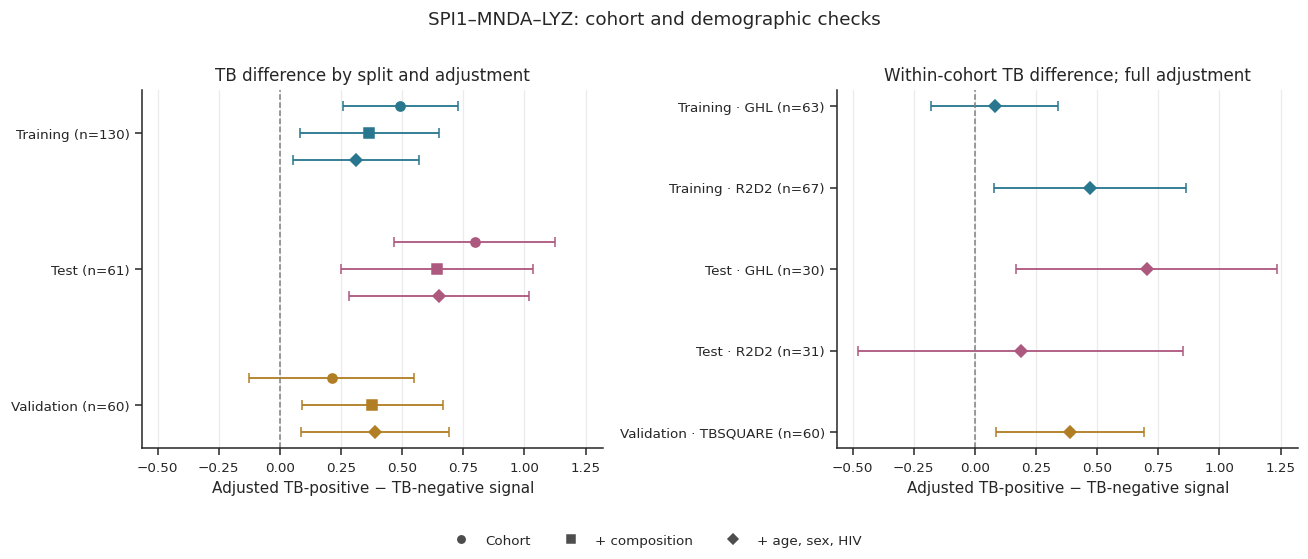

,split,n,estimate,ci_lower,ci_upper,p_value,q_primary_family
2,train,130,0.3098,0.0526,0.5670,0.0186,0.0186
5,test,61,0.6520,0.2846,1.0193,0.0008,0.0024
8,val,60,0.3893,0.0882,0.6905,0.0123,0.0184


In [4]:
tb_rows, cohort_rows = [], []
for split, frame in analysis.groupby("split", sort=False):
    for adjustment, covariates in ADJUSTMENTS.items():
        result, _ = fit_effect(frame, "tb_positive", covariates)
        tb_rows.append({"split": split, "adjustment": adjustment, **result})
    for cohort, subset in frame.groupby("cohort", sort=False):
        result, _ = fit_effect(subset, "tb_positive", ADJUSTMENTS[PRIMARY])
        cohort_rows.append({"split": split, "cohort": cohort, **result})
tb_results = pd.DataFrame(tb_rows)
primary_mask = tb_results.adjustment.eq(PRIMARY)
tb_results.loc[primary_mask, "q_primary_family"] = multipletests(
    tb_results.loc[primary_mask, "p_value"], method="fdr_bh")[1]
cohort_results = pd.DataFrame(cohort_rows)
tb_results.to_csv(OUTPUT / "cohort_clinical_tb_adjusted_associations.csv", index=False)
cohort_results.to_csv(OUTPUT / "cohort_clinical_tb_within_cohort_associations.csv", index=False)

figure, axes = plt.subplots(1, 2, figsize=(12, 4.9), sharex=True)
markers = {"Cohort": "o", "Cohort + composition": "s", PRIMARY: "D"}
short_labels = {"Cohort": "Cohort", "Cohort + composition": "+ composition", PRIMARY: "+ age, sex, HIV"}
for split_index, split in enumerate(SPLIT_NAMES):
    for adjustment_index, adjustment in enumerate(ADJUSTMENTS):
        row = tb_results.loc[tb_results.split.eq(split) & tb_results.adjustment.eq(adjustment)].iloc[0]
        y = split_index + (adjustment_index - 1) * 0.2
        axes[0].errorbar(row.estimate, y, xerr=[[row.estimate-row.ci_lower], [row.ci_upper-row.estimate]],
                         fmt=markers[adjustment], color=COLORS[split], capsize=3, markersize=6)
axes[0].set(yticks=range(3), yticklabels=[f"{name} (n={sum(analysis.split.eq(split))})" for split, name in SPLIT_NAMES.items()],
            title="TB difference by split and adjustment")
for i, row in cohort_results.iterrows():
    axes[1].errorbar(row.estimate, i, xerr=[[row.estimate-row.ci_lower], [row.ci_upper-row.estimate]],
                     fmt="D", color=COLORS[row.split], capsize=3, markersize=6)
axes[1].set(yticks=range(len(cohort_results)),
            yticklabels=[f"{SPLIT_NAMES[r.split]} · {r.cohort} (n={r.n})" for r in cohort_results.itertuples()],
            title="Within-cohort TB difference; full adjustment")
for axis in axes:
    axis.axvline(0, color="0.5", linestyle="--", linewidth=1)
    axis.invert_yaxis()
    axis.set_xlabel("Adjusted TB-positive − TB-negative signal")
    axis.grid(axis="x", color="0.92")
figure.legend(handles=[Line2D([], [], color="0.3", marker=markers[a], linestyle="", label=short_labels[a])
                       for a in ADJUSTMENTS], loc="lower center", ncol=3, frameon=False)
figure.suptitle("SPI1–MNDA–LYZ: cohort and demographic checks", y=1.01)
figure.tight_layout(rect=(0, 0.08, 1, 1))
save_figure(figure, "cohort_adjusted_tb_effects")
plt.show()
display(tb_results.loc[primary_mask, ["split", "n", "estimate", "ci_lower", "ci_upper", "p_value", "q_primary_family"]].round(4))

### Cohort heterogeneity and one technical sensitivity

For training and test, fit cohort-specific slopes for TB and every nuisance covariate, and report the R2D2-minus-GHL difference in TB coefficients. This reproduces the separate-cohort point estimates above while supplying a direct interaction interval. Lack of an interaction is not proof of equivalence.

The technical sensitivity adds log10 exonic read depth, centered within cohort/split, to the full model. It is a precision/depth check; read yield can also carry biology, so this is not automatically a better adjustment.

In [5]:
heterogeneity_rows, depth_rows = [], []
for split, frame in analysis.groupby("split", sort=False):
    if frame.cohort.nunique() == 2:
        numeric_terms = ["tb_positive", *COMPOSITION, *DEMOGRAPHICS]
        formula = "three_gene_signal ~ C(cohort) * (" + " + ".join(numeric_terms) + ")"
        model = smf.ols(formula, data=frame).fit(cov_type="HC3", use_t=True)
        assert np.linalg.matrix_rank(model.model.exog) == model.model.exog.shape[1]
        term = "C(cohort)[T.R2D2]:tb_positive"
        separate = cohort_results.loc[cohort_results.split.eq(split)].set_index("cohort")
        np.testing.assert_allclose(model.params[term], separate.loc["R2D2", "estimate"] - separate.loc["GHL", "estimate"])
        lower, upper = model.conf_int().loc[term]
        heterogeneity_rows.append({"split": split, "n": len(frame), "difference_R2D2_minus_GHL": model.params[term],
                                   "ci_lower": lower, "ci_upper": upper, "p_value": model.pvalues[term],
                                   "formula": model.model.formula})
    result, _ = fit_effect(frame, "tb_positive", [*ADJUSTMENTS[PRIMARY], "depth_within_cohort"])
    depth_rows.append({"split": split, **result})
heterogeneity = pd.DataFrame(heterogeneity_rows)
depth_sensitivity = pd.DataFrame(depth_rows)
heterogeneity.to_csv(OUTPUT / "cohort_clinical_tb_cohort_interactions.csv", index=False)
depth_sensitivity.to_csv(OUTPUT / "cohort_clinical_tb_read_depth_sensitivity.csv", index=False)
display(heterogeneity.drop(columns="formula").round(4))
display(depth_sensitivity.drop(columns="formula").round(4))

,split,n,difference_R2D2_minus_GHL,ci_lower,ci_upper,p_value
0,train,130,0.3908,-0.0746,0.8563,0.0989
1,test,61,-0.5156,-1.3434,0.3122,0.2162


,split,n,excluded,estimate,ci_lower,ci_upper,p_value,df_resid
0,train,130,0,0.2669,-0.0122,0.5459,0.0607,120.0
1,test,61,0,0.6392,0.2455,1.0329,0.0020,51.0
2,val,60,0,0.3933,0.0595,0.7270,0.0218,51.0


**Interpretation:** the fully adjusted signal is positive at the split level, but individual cohort estimates have wide intervals. Training GHL and test R2D2 are compatible with no residual TB difference. The estimated interaction changes direction between training and test, so these data do not establish a stable cohort-specific effect. Exonic-read adjustment makes the training interval include zero while test and validation remain positive.

## 5. Distinguish monocyte and neutrophil contributions

As a sensitivity analysis, replace the total-myeloid log ratio by three log ratios: monocyte, neutrophil and the remaining myeloid types, all relative to the same non-myeloid/non-lymphoid/non-erythroid-platelet denominator used before. Keep lymphoid and erythroid/platelet log ratios, TB, cohort and demographics.

These six mutually exclusive source groups exhaust the estimated cfRNA mixture. A coefficient is the signal change per one natural-log unit of a source/reference ratio at fixed other ratios; it is not an effect per extra cell. Closely related RNA-source estimates may produce wide or unstable intervals.

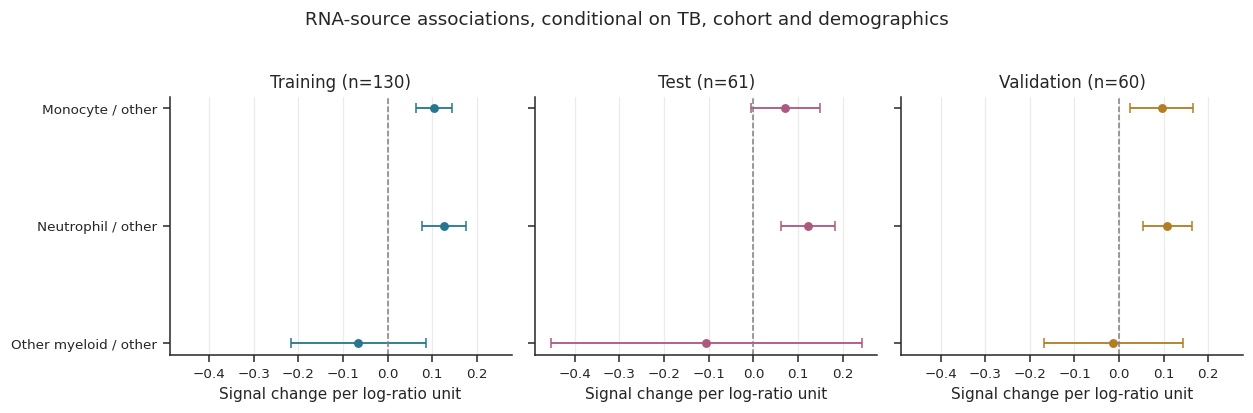

,split,n,excluded,estimate,ci_lower,ci_upper,p_value,df_resid
0,train,130,0,0.1696,-0.0306,0.3697,0.0961,119.0
1,test,61,0,0.5358,0.2360,0.8356,0.0008,50.0
2,val,60,0,0.1760,-0.1286,0.4805,0.2513,50.0


In [6]:
fractions = pd.read_csv(DATA / "discovery_cell_types.tsv", sep="\t", index_col="sample_id").loc[analysis.index]
groups = pd.read_csv(FOCUSED / "myeloid_rna_groups.csv", index_col="sample_id").loc[analysis.index]
source_parts = pd.DataFrame({
    "monocyte": fractions.Monocyte,
    "neutrophil": fractions.neutrophil,
    "other_myeloid": groups.myeloid - fractions.Monocyte - fractions.neutrophil,
    "lymphoid": groups.lymphoid, "erythroid_platelet": groups.erythroid_platelet, "other": groups.other,
})
assert (source_parts > 0).all().all()
np.testing.assert_allclose(source_parts.sum(axis=1), 1, atol=1e-8)
source_terms = []
for source in ["monocyte", "neutrophil", "other_myeloid"]:
    term = f"{source}_vs_other"
    analysis[term] = np.log(source_parts[source] / source_parts.other)
    source_terms.append(term)
separate_composition = [*source_terms, *COMPOSITION[1:]]
source_rows, source_tb_rows = [], []
for split, frame in analysis.groupby("split", sort=False):
    result, model = fit_effect(frame, "tb_positive", ["cohort", *separate_composition, *DEMOGRAPHICS])
    source_tb_rows.append({"split": split, **result})
    for source, term in zip(["Monocyte", "Neutrophil", "Other myeloid"], source_terms):
        lower, upper = model.conf_int().loc[term]
        source_rows.append({"split": split, "source": source, "n": len(frame),
                            "estimate": model.params[term], "ci_lower": lower, "ci_upper": upper,
                            "p_value": model.pvalues[term]})
source_results = pd.DataFrame(source_rows)
source_tb_results = pd.DataFrame(source_tb_rows)
source_results.to_csv(OUTPUT / "cohort_clinical_separate_myeloid_source_coefficients.csv", index=False)
source_tb_results.to_csv(OUTPUT / "cohort_clinical_tb_separate_myeloid_adjustment.csv", index=False)
figure, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), sharex=True, sharey=True)
for axis, split in zip(axes, SPLIT_NAMES):
    subset = source_results.loc[source_results.split.eq(split)].reset_index(drop=True)
    for i, row in subset.iterrows():
        axis.errorbar(row.estimate, i, xerr=[[row.estimate-row.ci_lower], [row.ci_upper-row.estimate]],
                      fmt="o", color=COLORS[split], capsize=3)
    axis.axvline(0, color="0.5", linestyle="--", linewidth=1)
    axis.set(title=f"{SPLIT_NAMES[split]} (n={subset.n.iloc[0]})", xlabel="Signal change per log-ratio unit")
    axis.grid(axis="x", color="0.92")
axes[0].set_yticks(range(3), ["Monocyte / other", "Neutrophil / other", "Other myeloid / other"])
axes[0].invert_yaxis()
figure.suptitle("RNA-source associations, conditional on TB, cohort and demographics", y=1.03)
figure.tight_layout()
save_figure(figure, "separate_myeloid_source_associations")
plt.show()
display(source_tb_results.drop(columns="formula").round(4))

**Interpretation:** monocyte and neutrophil source ratios each have positive conditional coefficients; the monocyte test interval includes zero. However, this more detailed composition adjustment reduces the TB coefficient to 0.170 in training and 0.176 in validation, with both 95% intervals crossing zero. Test remains positive at 0.536. This weakens a claim of composition-independent cellular activation; it does not prove the association is entirely explained by composition.

## 6. Xpert Ultra categories among TB-positive participants

The assay is a sputum microbial-burden proxy, not a direct measure of cfRNA source or overall clinical severity. Each panel shows only participants with an available Low, Medium or High result. Category numbers are used only in the following trend model. Points retain cohort identity; boxes show the median and interquartile range, with 1.5-IQR whiskers.

tb_positive_n  available_n  missing_n  Low  Medium  High
split cohort                                                            
train GHL                  39           34          5    9      11    14
      R2D2                 34           34          0    7      17    10
test  GHL                  18           16          2    5       5     6
      R2D2                 16           16          0    3       3    10
val   TBSQUARE             35           35          0    8      14    13

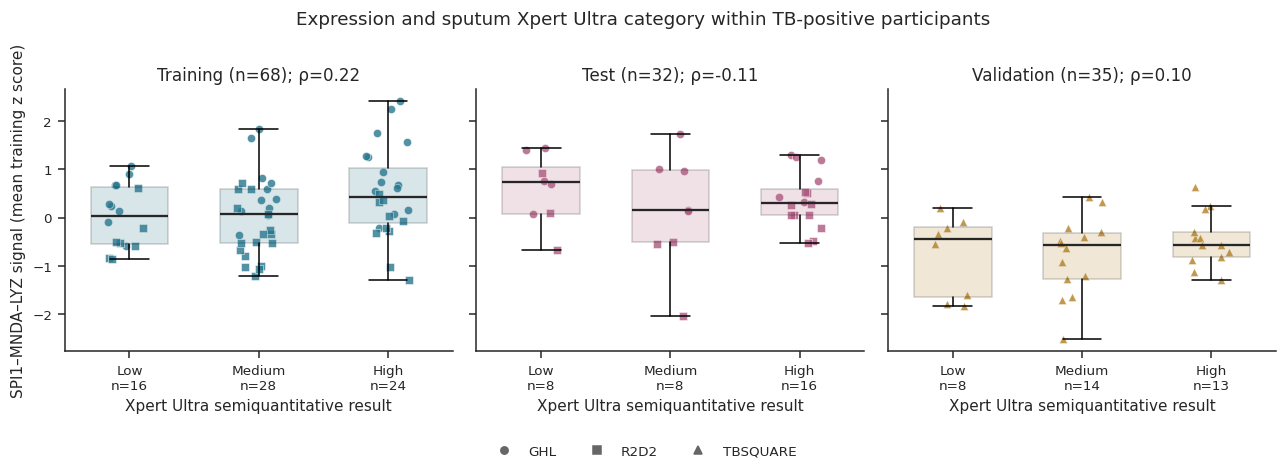

In [7]:
BURDEN_ORDER = ["Low", "Medium", "High"]
tb_positive = analysis.loc[analysis.tb_positive.eq(1)].copy()
assert tb_positive.semiquant.dropna().isin(BURDEN_ORDER).all()
burden_coverage = tb_positive.groupby(["split", "cohort"], sort=False).agg(
    tb_positive_n=("tb_positive", "size"), available_n=("semiquant", "count"))
burden_coverage["missing_n"] = burden_coverage.tb_positive_n - burden_coverage.available_n
burden_coverage.to_csv(OUTPUT / "cohort_clinical_burden_coverage.csv")
burden = tb_positive.loc[tb_positive.semiquant.isin(BURDEN_ORDER)].copy()
burden["burden_order"] = burden.semiquant.map({"Low": 0, "Medium": 1, "High": 2})
assert len(burden) == 135 and not burden.burden_order.isna().any()
burden_counts = pd.crosstab([burden.split, burden.cohort], burden.semiquant).reindex(columns=BURDEN_ORDER)
burden_counts.to_csv(OUTPUT / "cohort_clinical_burden_category_counts.csv")
display(burden_coverage.join(burden_counts))

figure, axes = plt.subplots(1, 3, figsize=(11.8, 4.1), sharey=True)
rng = np.random.default_rng(SEED)
cohort_markers = {"GHL": "o", "R2D2": "s", "TBSQUARE": "^"}
for axis, split in zip(axes, SPLIT_NAMES):
    frame = burden.loc[burden.split.eq(split)]
    values = [frame.loc[frame.semiquant.eq(category), "three_gene_signal"] for category in BURDEN_ORDER]
    boxes = axis.boxplot(values, positions=range(3), widths=0.6, patch_artist=True, showfliers=False,
                         medianprops={"color": "0.15", "linewidth": 1.5})
    for box in boxes["boxes"]:
        box.set(facecolor=COLORS[split], alpha=0.18)
    for cohort, subset in frame.groupby("cohort", sort=False):
        axis.scatter(subset.burden_order + rng.uniform(-0.17, 0.17, len(subset)), subset.three_gene_signal,
                     color=COLORS[split], marker=cohort_markers[cohort], s=29, alpha=0.8,
                     edgecolor="white", linewidth=0.4)
    rho = spearmanr(frame.burden_order, frame.three_gene_signal).statistic
    axis.set(title=f"{SPLIT_NAMES[split]} (n={len(frame)}); ρ={rho:.2f}",
             xticks=range(3), xticklabels=[f"{category}\nn={len(v)}" for category, v in zip(BURDEN_ORDER, values)],
             xlabel="Xpert Ultra semiquantitative result")
axes[0].set_ylabel("SPI1–MNDA–LYZ signal (mean training z score)")
figure.legend(handles=[Line2D([], [], color="0.4", marker=marker, linestyle="", label=cohort)
                       for cohort, marker in cohort_markers.items()], loc="lower center", ncol=3, frameon=False)
figure.suptitle("Expression and sputum Xpert Ultra category within TB-positive participants", y=1.01)
figure.tight_layout(rect=(0, 0.08, 1, 1))
save_figure(figure, "tb_positive_burden_distributions")
plt.show()

### Ordered-category trends with covariate adjustment

Use the same available TB-positive participants in all three models: cohort alone; cohort plus age, sex and HIV; and additionally the primary composition log ratios. Do not combine TB-negative status with Low/Medium/High to manufacture a disease-burden trend. A slope is the average signal difference per category step, with the distributions above revealing deviations from a monotonic pattern.

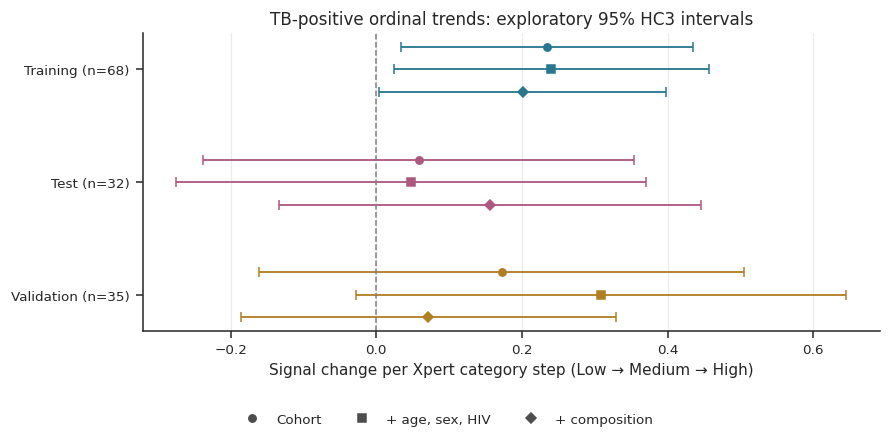

,split,n,estimate,ci_lower,ci_upper,p_value,q_primary_family
2,train,68,0.2008,0.0040,0.3976,0.0457,0.1370
5,test,32,0.1563,-0.1335,0.4461,0.2762,0.4143
8,val,35,0.0716,-0.1854,0.3286,0.5724,0.5724


In [8]:
BURDEN_ADJUSTMENTS = {
    "Cohort": ["cohort"],
    "Cohort + demographics": ["cohort", *DEMOGRAPHICS],
    "Cohort + demographics + composition": ["cohort", *DEMOGRAPHICS, *COMPOSITION],
}
BURDEN_PRIMARY = "Cohort + demographics + composition"
burden_rows, rank_rows = [], []
for split, frame in burden.groupby("split", sort=False):
    rho, p_value = spearmanr(frame.burden_order, frame.three_gene_signal)
    rank_rows.append({"split": split, "n": len(frame), "spearman_rho": rho, "p_value": p_value})
    for adjustment, covariates in BURDEN_ADJUSTMENTS.items():
        result, _ = fit_effect(frame, "burden_order", covariates)
        burden_rows.append({"split": split, "adjustment": adjustment, **result})
burden_results = pd.DataFrame(burden_rows)
burden_primary_mask = burden_results.adjustment.eq(BURDEN_PRIMARY)
burden_results.loc[burden_primary_mask, "q_primary_family"] = multipletests(
    burden_results.loc[burden_primary_mask, "p_value"], method="fdr_bh")[1]
burden_ranks = pd.DataFrame(rank_rows)
burden_results.to_csv(OUTPUT / "cohort_clinical_burden_adjusted_trends.csv", index=False)
burden_ranks.to_csv(OUTPUT / "cohort_clinical_burden_spearman_correlations.csv", index=False)

figure, axis = plt.subplots(figsize=(8.2, 4))
for split_index, split in enumerate(SPLIT_NAMES):
    for adjustment_index, adjustment in enumerate(BURDEN_ADJUSTMENTS):
        row = burden_results.loc[burden_results.split.eq(split) & burden_results.adjustment.eq(adjustment)].iloc[0]
        axis.errorbar(row.estimate, split_index + (adjustment_index-1)*0.2,
                      xerr=[[row.estimate-row.ci_lower], [row.ci_upper-row.estimate]],
                      fmt=["o", "s", "D"][adjustment_index], color=COLORS[split], capsize=3)
axis.axvline(0, color="0.5", linestyle="--", linewidth=1)
axis.set(yticks=range(3), yticklabels=[f"{name} (n={sum(burden.split.eq(split))})" for split, name in SPLIT_NAMES.items()],
         xlabel="Signal change per Xpert category step (Low → Medium → High)",
         title="TB-positive ordinal trends: exploratory 95% HC3 intervals")
axis.invert_yaxis()
axis.grid(axis="x", color="0.92")
figure.legend(handles=[Line2D([], [], color="0.3", marker=marker, linestyle="", label=label)
                       for marker, label in zip(["o", "s", "D"], ["Cohort", "+ age, sex, HIV", "+ composition"])],
              loc="lower center", ncol=3, frameon=False)
figure.tight_layout(rect=(0, 0.09, 1, 1))
save_figure(figure, "tb_positive_burden_trends")
plt.show()
display(burden_results.loc[burden_primary_mask, ["split", "n", "estimate", "ci_lower", "ci_upper", "p_value", "q_primary_family"]].round(4))

**Interpretation:** the fully adjusted training slope is positive, but it does not survive the three-split BH correction (q=0.137), and the test and validation intervals include zero. The raw rank correlations are weak and change direction. This signal currently has clearer evidence as a TB-associated RNA-source signal than as a marker of sputum microbial burden. The seven missing results are all in GHL; complete-case analysis cannot remove any selection bias from those missing measurements.

## 7. Observed results and reproducibility

The following summary is generated from the same exact-value tables used in the plots. These conditional associations help prioritize biological hypotheses; they do not establish mediation, immune-cell activation, or a relationship to all dimensions of TB severity.

These completed results use the existing plasma fractions. The [gene-excluded deconvolution companion](gene_interactions_deconvolution.ipynb) is an **optional robustness check**, not a prerequisite for this analysis.

In [9]:
summary_lines = []
for split in SPLIT_NAMES:
    tb = tb_results.loc[tb_results.split.eq(split) & primary_mask].iloc[0]
    clinical = burden_results.loc[burden_results.split.eq(split) & burden_primary_mask].iloc[0]
    summary_lines.append(
        f"- **{SPLIT_NAMES[split]}:** fully adjusted TB difference **{tb.estimate:.3f}** "
        f"(95% CI {tb.ci_lower:.3f} to {tb.ci_upper:.3f}; n={tb.n}; q={tb.q_primary_family:.3g}). "
        f"Within TB-positive participants, adjusted Xpert-category slope **{clinical.estimate:.3f}** "
        f"({clinical.ci_lower:.3f} to {clinical.ci_upper:.3f}; n={clinical.n}; q={clinical.q_primary_family:.3g}).")
display(Markdown("\n".join(summary_lines)))
analysis.to_csv(OUTPUT / "cohort_clinical_analysis_inputs.csv")
input_paths = [FOCUSED / "myeloid_analysis_inputs.csv", FOCUSED / "myeloid_rna_groups.csv",
               FOCUSED / "myeloid_group_definitions.json", DATA / "discovery_cell_types.tsv",
               *[DATA / f"metadata.{split}.tsv" for split in SPLIT_NAMES]]
provenance = {
    "inputs_sha256": {str(path.relative_to(REPOSITORY)): hashlib.sha256(path.read_bytes()).hexdigest() for path in input_paths},
    "packages": {package: version(package) for package in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]},
    "signal": "Existing mean training z score of SPI1, MNDA and LYZ",
    "tb_primary_covariates": ADJUSTMENTS[PRIMARY],
    "burden_primary_covariates": BURDEN_ADJUSTMENTS[BURDEN_PRIMARY],
    "intervals": "95% HC3 covariance, residual-df t",
    "burden_source": "Figure_2.ipynb Fig2G axis and PMC11164910 Figure 2 caption: Xpert Ultra semiquantitative result",
    "burden_encoding": {"Low": 0, "Medium": 1, "High": 2},
    "multiple_testing": "BH separately for 3 primary fully adjusted TB tests and 3 primary burden trends",
    "limitations": ["TB-selected genes and previously inspected datasets: exploratory inference",
                    "Same-RNA source estimates do not establish cell-intrinsic responses",
                    "Ordinal categories are not calibrated bacterial counts"],
}
(OUTPUT / "cohort_clinical_provenance.json").write_text(json.dumps(provenance, indent=2))
print(f"Saved exact-value tables and four figures to {OUTPUT}")

- **Training:** fully adjusted TB difference **0.310** (95% CI 0.053 to 0.567; n=130; q=0.0186). Within TB-positive participants, adjusted Xpert-category slope **0.201** (0.004 to 0.398; n=68; q=0.137).
- **Test:** fully adjusted TB difference **0.652** (95% CI 0.285 to 1.019; n=61; q=0.0024). Within TB-positive participants, adjusted Xpert-category slope **0.156** (-0.134 to 0.446; n=32; q=0.414).
- **Validation:** fully adjusted TB difference **0.389** (95% CI 0.088 to 0.691; n=60; q=0.0184). Within TB-positive participants, adjusted Xpert-category slope **0.072** (-0.185 to 0.329; n=35; q=0.572).

Saved exact-value tables and four figures to /local/workdir/amz63/cfRNA_TB/Figure_Output/Gene_Interactions/focused
